(i): tau_I = 10 ms
epsilon   period    amplitude                     lag
  0.005       12.6990       0.0197              73.5528
  0.010       12.8113       0.0279              71.3969
  0.020       13.0355       0.0394              68.3576
  0.050       13.7062       0.0621              62.5193
  0.100       14.8221       0.0874              56.5478
  0.200       17.0834       0.1231              49.7429

 slope = 0.4964

(ii):epsilon=0.02
tau_I (ms)   prediction    simulation
      2.00         162.7744         157.0560
      3.00         138.0974         133.3969
      5.00         110.0818         106.3556
      7.50          91.1254          88.0145
     10.00          79.4500          76.7134
     15.00          65.3031          63.0216
     20.00          56.7405          54.7370


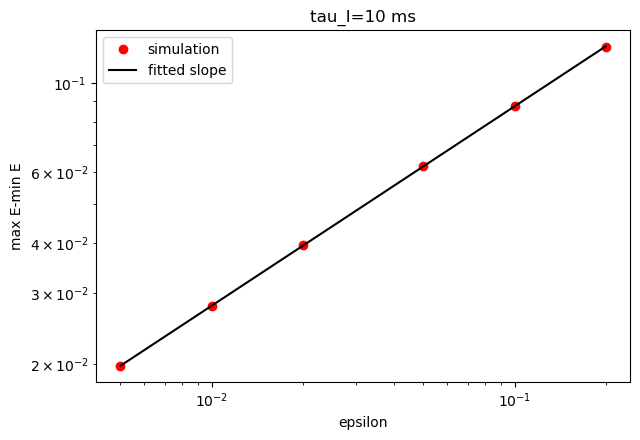

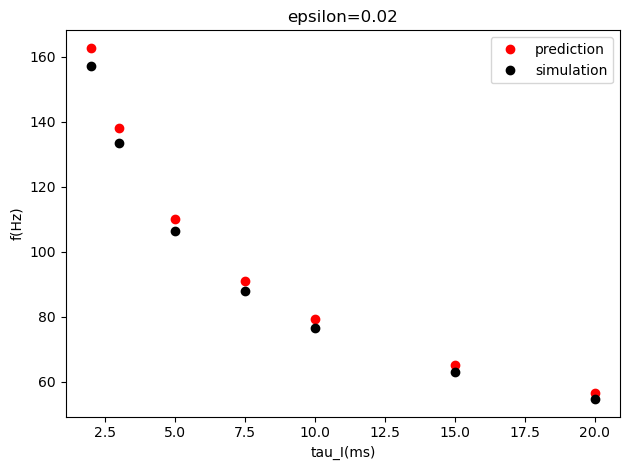

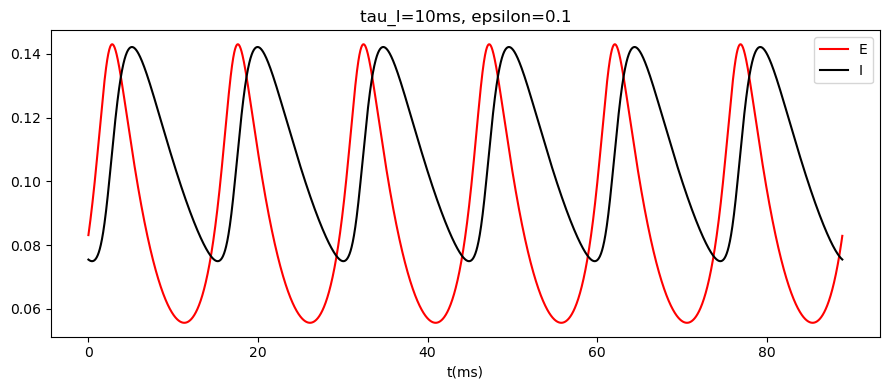

In [26]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.special import expit
from scipy.signal import find_peaks

eta = 4.0
tau_E = 5.0
w_EI = 10.0
w_IE = 10.0

E_bar = 0.1
I_bar = 0.1

s_E = eta * E_bar * (1.0 - E_bar)
s_I = eta * I_bar * (1.0 - I_bar)

B = s_E * s_I * w_EI * w_IE / tau_E


def hopf_weight(tau_I):
    return (1.0 + tau_E / tau_I) / s_E


def hopf_frequency(tau_I):
    omega = np.sqrt(B / tau_I - 1.0 / tau_I**2)
    return 1000.0 * omega / (2.0 * np.pi)


def interpolated_peaks(t, y):
    indices, _ = find_peaks(y)

    left = y[indices - 1]
    middle = y[indices]
    right = y[indices + 1]

    offset = (
        0.5 * (left - right)
        / (left - 2.0 * middle + right)
    )

    dt = t[1] - t[0]

    peak_times = t[indices] + offset * dt
    peak_values = middle - 0.25 * (left - right) * offset

    return peak_times, peak_values

def simulate(tau_I, epsilon):
    w_EE = (1.0 + epsilon) * hopf_weight(tau_I)

    p_E = (
        np.log(E_bar / (1.0 - E_bar)) / eta
        - w_EE * E_bar
        + w_EI * I_bar
    )

    p_I = (
        np.log(I_bar / (1.0 - I_bar)) / eta
        - w_IE * E_bar
    )

    def rhs(t, y):
        E, I = y

        dE = (
            -E + expit(eta * (w_EE * E - w_EI * I + p_E))
        ) / tau_E

        dI = (
            -I + expit(eta * (w_IE * E + p_I))
        ) / tau_I

        return [dE, dI]

    growth_rate = (
        0.5 * epsilon * (1.0 / tau_E + 1.0 / tau_I)
    )

    transient = max(2000.0, 30.0 / growth_rate)
    measurement_time = 1000.0

    solution = solve_ivp(
        rhs,
        (0.0, transient + measurement_time),
        [E_bar + 0.001, I_bar],
        method="DOP853",
        rtol=2e-10,
        atol=1e-12,
        max_step=1.0,
        dense_output=True,
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    t = np.arange(
        transient,
        transient + measurement_time,
        0.02,
    )

    E, I = solution.sol(t)

    E_peak_times, E_peak_values = interpolated_peaks(t, E)
    I_peak_times, _ = interpolated_peaks(t, I)

    _, negative_E_minima = interpolated_peaks(t, -E)

    if len(E_peak_times) < 3 or len(I_peak_times) < 3:
        raise RuntimeError("error")

    periods = np.diff(E_peak_times)
    period = np.mean(periods)

    amplitude = (
        np.mean(E_peak_values) + np.mean(negative_E_minima)
    )

    # For each E peak, locate the following I peak.
    following = np.searchsorted(I_peak_times, E_peak_times)
    valid = following < len(I_peak_times)

    time_lags = (
        I_peak_times[following[valid]] - E_peak_times[valid]
    )

    lag_degrees = 360.0 * np.mean(time_lags) / period

    return {
        "tau_I": tau_I,
        "epsilon": epsilon,
        "period": period,
        "amplitude": amplitude,
        "lag_degrees": lag_degrees,
        "frequency": 1000.0 / period,
        "t": t - transient,
        "E": E,
        "I": I,
    }



epsilon_values = np.array([
    0.005, 0.01, 0.02, 0.05, 0.1, 0.2
])

epsilon_results = [
    simulate(tau_I=10.0, epsilon=eps)
    for eps in epsilon_values
]

print("(i): tau_I = 10 ms")
print("epsilon   period    amplitude                     lag")

for result in epsilon_results:
    print(
        f"{result['epsilon']:7.3f}   "
        f"{result['period']:11.4f}   "
        f"{result['amplitude']:10.4f}   "
        f"{result['lag_degrees']:18.4f}"
    )

amplitudes = np.array([
    result["amplitude"] for result in epsilon_results
])

slope, intercept = np.polyfit(
    np.log(epsilon_values),
    np.log(amplitudes),
    1,
)

print(f"\n slope = {slope:.4f}")

epsilon_fit = np.geomspace(
    epsilon_values.min(),
    epsilon_values.max(),
    200,
)

amplitude_fit = np.exp(intercept) * epsilon_fit**slope

plt.figure(figsize=(6.5, 4.5))
plt.loglog(
    epsilon_values,
    amplitudes,
    "o",
    color="red",
    label="simulation",
)
plt.loglog(
    epsilon_fit,
    amplitude_fit,
    color="black",
    label=f"fitted slope",
)
plt.xlabel("epsilon")
plt.ylabel("max E-min E")
plt.title("tau_I=10 ms")
plt.legend()
plt.tight_layout()


tau_I_values = np.array([
    2, 3, 5, 7.5, 10, 15, 20
])

# Reuse the tau_I=10, epsilon=0.02 result.
result_at_10 = epsilon_results[2]

tau_results = [
    result_at_10 if tau_I == 10.0
    else simulate(tau_I=tau_I, epsilon=0.02)
    for tau_I in tau_I_values
]

predicted_frequencies = hopf_frequency(tau_I_values)

simulated_frequencies = np.array([
    result["frequency"] for result in tau_results
])

print("\n(ii):epsilon=0.02")
print("tau_I (ms)   prediction    simulation")

for tau_I, predicted, simulated in zip(
    tau_I_values,
    predicted_frequencies,
    simulated_frequencies,
):
    print(
        f"{tau_I:10.2f}   "
        f"{predicted:14.4f}   "
        f"{simulated:14.4f}"
    )

plt.figure()
plt.plot(
    tau_I_values,
    predicted_frequencies,
    "o",
    color="red",
    label="prediction",
)
plt.plot(
    tau_I_values,
    simulated_frequencies,
    "o",
    color="black",
    label="simulation",
)
plt.xlabel("tau_I(ms)")
plt.ylabel("f(Hz)")
plt.title("epsilon=0.02")
plt.legend()
plt.tight_layout()



result = epsilon_results[4]

mask = result["t"] <= 6.0 * result["period"]

plt.figure(figsize=(9, 4))
plt.plot(
    result["t"][mask],
    result["E"][mask],
    color="red",
    label="E",
)
plt.plot(
    result["t"][mask],
    result["I"][mask],
    color="black",
    label="I",
)
plt.xlabel("t(ms)")
plt.title("tau_I=10ms, epsilon=0.1")
plt.legend()
plt.tight_layout()

plt.show()


(ii)
 I_L      TL sim        TL theory     TR sim       TR theory
 1.30            208         208            208         208
 1.45            197         197            160         159
 1.60            186         185            127         125

(iii)
mean T_L:          166
mean T_R:          167
sim T_dom:   167
theory T_dom:  166


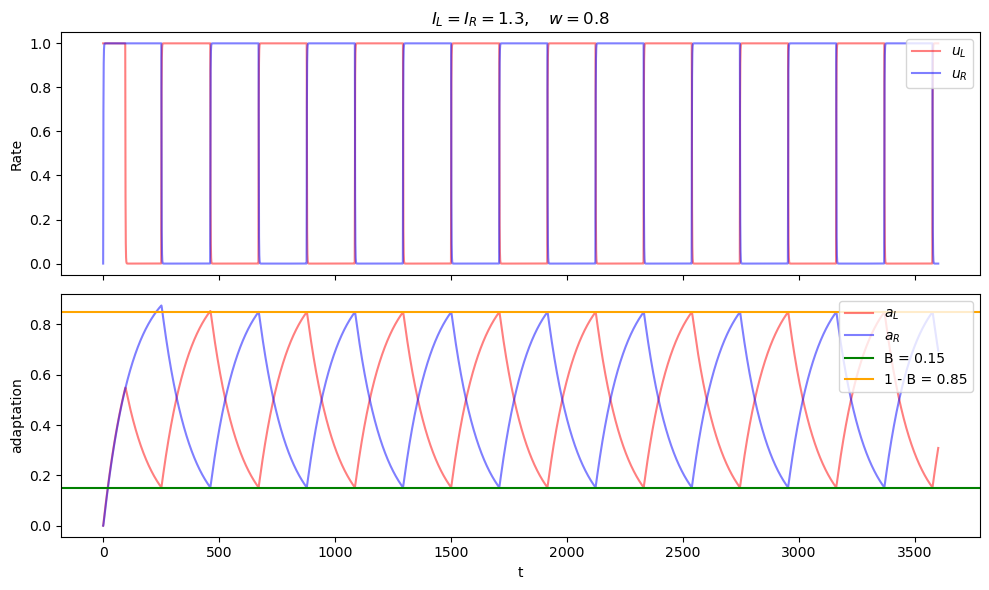

In [27]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.special import expit

beta = 1.0
g = 2.0
tau_a = 120.0
eta = 1000.0

I_R = 1.3
T_end = 30.0 * tau_a

initial_state = [1.0, 0.0, 0.0, 0.0]


def simulate(I_L, w=0.8):

    def rhs(t, y):
        u_L, u_R, a_L, a_R = y

        input_L = w * u_L - beta * u_R - g * a_L + I_L
        input_R = w * u_R - beta * u_L - g * a_R + I_R

        du_L = -u_L + expit(eta * input_L)
        du_R = -u_R + expit(eta * input_R)

        da_L = (-a_L + u_L) / tau_a
        da_R = (-a_R + u_R) / tau_a

        return [du_L, du_R, da_L, da_R]

    def left_dominant(t, y):
        return y[0] - y[1] - 0.5

    def right_dominant(t, y):
        return y[1] - y[0] - 0.5

    left_dominant.direction = 1
    right_dominant.direction = 1

    sol = solve_ivp(
        rhs,
        (0.0, T_end),
        initial_state,
        method="Radau",
        rtol=1e-8,
        atol=1e-10,
        max_step=1.0,
        dense_output=True,
        events=[left_dominant, right_dominant],
    )

    if not sol.success:
        raise RuntimeError(sol.message)

    return sol


def dominance_durations(sol):

    # Label 0 = L, label 1 = R.
    events = sorted(
        [(t, 0) for t in sol.t_events[0]]
        + [(t, 1) for t in sol.t_events[1]]
    )

    # Initially L is dominant.
    handovers = [(0.0, 0)]

    for time, label in events:
        if label != handovers[-1][1]:
            handovers.append((time, label))

    durations = []

    for j in range(len(handovers) - 1):
        start, label = handovers[j]
        end = handovers[j + 1][0]
        durations.append((end - start, label))

    # Discard the first three completed intervals.
    durations = durations[3:]

    T_L = np.array([
        duration for duration, label in durations
        if label == 0
    ])

    T_R = np.array([
        duration for duration, label in durations
        if label == 1
    ])

    return T_L, T_R


def analytical_times(I_L):
    B_L = (I_L - beta) / g
    B_R = (I_R - beta) / g

    T_L = tau_a * np.log((1.0 - B_L) / B_R)
    T_R = tau_a * np.log((1.0 - B_R) / B_L)

    return T_L, T_R


# Part (i)
sol_equal = simulate(I_L=1.3, w=0.8)

t = np.linspace(0.0, T_end, 18001)
u_L, u_R, a_L, a_R = sol_equal.sol(t)

B = (1.3 - beta) / g

fig, ax = plt.subplots(
    2, 1,
    figsize=(10, 6),
    sharex=True,
)

ax[0].plot(
    t, u_L, color="red", alpha=0.5, label=r"$u_L$"
)
ax[0].plot(
    t, u_R, color="blue", alpha=0.5, label=r"$u_R$"
)
ax[0].set_ylabel("Rate")
ax[0].set_title(r"$I_L=I_R=1.3,\quad w=0.8$")
ax[0].legend(loc="upper right")

ax[1].plot(
    t, a_L, color="red", alpha=0.5, label=r"$a_L$"
)
ax[1].plot(
    t, a_R, color="blue", alpha=0.5, label=r"$a_R$"
)

ax[1].axhline(
    B,
    color="green",
    label=f"B = {B:.2f}",
)

ax[1].axhline(
    1.0 - B,
    color="orange",
    label=f"1 - B = {1.0 - B:.2f}",
)

ax[1].set_xlabel("t")
ax[1].set_ylabel("adaptation")
ax[1].legend(loc="upper right")

plt.tight_layout()


# Part (ii)
print("\n(ii)")

print(
    " I_L      TL sim        TL theory"
    "     TR sim       TR theory"
)

for I_L in [1.3, 1.45, 1.6]:

    sol = (
        sol_equal if I_L == 1.3
        else simulate(I_L=I_L, w=0.8)
    )

    durations_L, durations_R = dominance_durations(sol)

    mean_L = np.mean(durations_L)
    mean_R = np.mean(durations_R)

    theory_L, theory_R = analytical_times(I_L)

    print(
        f"{I_L:5.2f}"
        f"   {mean_L:12.3g}"
        f"   {theory_L:9.3g}"
        f"   {mean_R:12.3g}"
        f"   {theory_R:9.3g}"
    )


# Part (iii)
w = 0.3
I = 1.3

sol_low_w = simulate(I_L=I, w=w)

durations_L, durations_R = dominance_durations(sol_low_w)

mean_L = np.mean(durations_L)
mean_R = np.mean(durations_R)

T_dom_sim = 0.5 * (mean_L + mean_R)

T_dom_theory = tau_a * np.log(
    (w + I) / (g - w - I)
)

print("\n(iii)")
print(f"mean T_L:          {mean_L:.3g}")
print(f"mean T_R:          {mean_R:.3g}")
print(f"sim T_dom:   {T_dom_sim:.3g}")
print(f"theory T_dom:  {T_dom_theory:.3g}")

plt.show()

k = 0.3
a_- = 0.2031
a_+  = 1.6941

k            slope                lambda_e
 0.10         -0.0902                 -0.0902
 0.30         -0.2111                 -0.2083
 0.45         -0.2013                 -0.1951


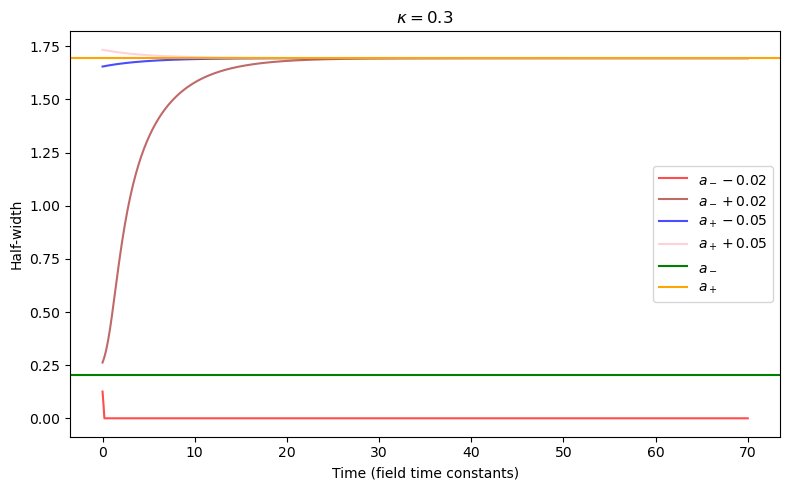

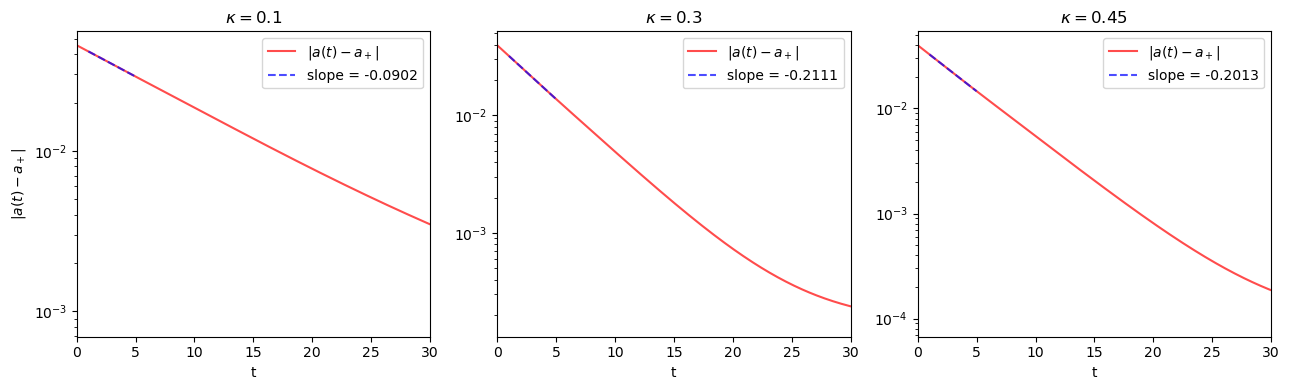

In [28]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.special import expit
from scipy.fft import rfft, irfft, next_fast_len


# Parameters
dx = 0.02
dt = 0.02
eta = 100.0

x = np.arange(-1000, 1001) * dx
N = len(x)


def w(z):
    return 2.0 * np.exp(-np.abs(z)) - np.exp(-np.abs(z) / 2.0)


def W(z):
    z = np.asarray(z)
    return (
        2.0 * np.sign(z)
        * (np.exp(-np.abs(z) / 2.0) - np.exp(-np.abs(z)))
    )


def bump_widths(kappa):
    S = np.sqrt(1.0 - 2.0 * kappa)

    a_minus = -np.log((1.0 + S) / 2.0)
    a_plus = -np.log((1.0 - S) / 2.0)

    return a_minus, a_plus


def lambda_even(a):
    return 2.0 * w(2.0 * a) / (w(0.0) - w(2.0 * a))


z = np.arange(-(N - 1), N) * dx
kernel = w(z)

fft_size = next_fast_len(N + len(kernel) - 1)
kernel_fft = rfft(kernel, fft_size) * dx


def convolution(activity):
    full = irfft(
        kernel_fft * rfft(activity, fft_size),
        fft_size,
    )

    return full[N - 1:N - 1 + N]


def half_width(u, kappa):
    active = np.flatnonzero(u >= kappa)

    if len(active) == 0:
        return 0.0

    j = active[-1]

    if j == N - 1:
        raise RuntimeError("error")

    return (
        x[j]
        + dx * (u[j] - kappa) / (u[j] - u[j + 1])
    )


def simulate(kappa, a0, T=70.0):
    u = W(x + a0) - W(x - a0)

    steps = int(round(T / dt))

    times = []
    widths = []

    for n in range(steps + 1):
        if n % 5 == 0:
            times.append(n * dt)
            widths.append(half_width(u, kappa))

        if n == steps:
            break

        firing_rate = expit(eta * (u - kappa))

        u += dt * (-u + convolution(firing_rate))

    return np.array(times), np.array(widths)


kappa = 0.3
a_minus, a_plus = bump_widths(kappa)

cases = [
    (a_minus - 0.02, r"$a_- - 0.02$", "red", "-"),
    (a_minus + 0.02, r"$a_- + 0.02$", "brown", "-"),
    (a_plus - 0.05, r"$a_+ - 0.05$", "blue", "-"),
    (a_plus + 0.05, r"$a_+ + 0.05$", "pink", "-"),
]

plt.figure(figsize=(8, 5))

print("k = 0.3")
print(f"a_- = {a_minus:.4f}")
print(f"a_+  = {a_plus:.4f}\n")

for a0, label, color, linestyle in cases:
    t, a = simulate(kappa, a0)

    plt.plot(
        t,
        a,
        color=color,
        linestyle=linestyle,
        alpha=0.7,
        label=label,
    )


plt.axhline(
    a_minus,
    color="green",
    label=r"$a_-$",
)

plt.axhline(
    a_plus,
    color="orange",
    label=r"$a_+$",
)

plt.xlabel("Time (field time constants)")
plt.ylabel("Half-width")
plt.title(r"$\kappa=0.3$")
plt.legend()
plt.tight_layout()


kappa_values = [0.1, 0.3, 0.45]

fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 4),
)


print("k            slope                lambda_e")

for ax, kappa in zip(axes, kappa_values):
    _, a_plus = bump_widths(kappa)

    t, a = simulate(
        kappa=kappa,
        a0=a_plus + 0.05,
        T=60.0,
    )

    deviation = np.abs(a - a_plus)

    mask = (
        (t >= 1.0)
        & (t <= 5.0)
        & (deviation > 0.0)
    )

    # log|a(t)-a_plus| = intercept + slope*t
    slope, intercept = np.polyfit(
        t[mask],
        np.log(deviation[mask]),
        1,
    )

    theoretical = lambda_even(a_plus)

    print(
        f"{kappa:5.2f}"
        f"    {slope:12.4f}"
        f"    {theoretical:20.4f}"
    )

    ax.semilogy(
        t,
        deviation,
        color="red",
        alpha=0.7,
        label=r"$|a(t)-a_+|$",
    )

    ax.semilogy(
        t[mask],
        np.exp(intercept + slope * t[mask]),
        color="blue",
        linestyle="--",
        alpha=0.7,
        label=f"slope = {slope:.4f}",
    )

    ax.set_xlabel("t")
    ax.set_title(rf"$\kappa={kappa}$")
    ax.set_xlim(0, 30)
    ax.legend()

axes[0].set_ylabel(r"$|a(t)-a_+|$")

plt.tight_layout()
plt.show()